# OpenAI Responses API — Teddy Bear 이미지 생성

Google Colab에서 순서대로 실행하세요. **Colab 비밀키(Secrets)**에 `OPENAI_API_KEY`를 저장하고 노트북 액세스를 허용해야 합니다. 이미지 생성에는 API 비용이 발생할 수 있습니다. 모델 및 도구 지원 여부는 계정 권한에 따라 다를 수 있습니다.

## Cell 1. OpenAI SDK 설치

In [ ]:
!pip -q install --upgrade openai

## Cell 2. API Key 및 클라이언트 설정

In [1]:
import os
from google.colab import userdata
from openai import OpenAI

api_key = userdata.get("OPENAI_API_KEY")
if not api_key:
    raise ValueError("Colab Secrets에서 OPENAI_API_KEY를 등록하세요.")

client = OpenAI(api_key=api_key)
print("OpenAI Client 초기화 완료")

OpenAI Client 초기화 완료


## Cell 3. Responses API로 이미지 생성

In [2]:
prompt = """
귀엽고 포근한 갈색 Teddy Bear가
두 손으로 커다란 현수막을 들고 있는 모습을 그려 주세요.

현수막에는 다음 한국어 문구를 정확하게 표시하세요.
"오늘도 수고 많으셨습니다!"

스타일:
- 귀여운 3D 캐릭터 일러스트
- 따뜻한 파스텔 색상
- 밝고 부드러운 배경
- 친근하고 행복한 표정
- 한국어 문구가 선명하게 보이도록 구성
"""

response = client.responses.create(
    model="gpt-6-luna",
    tools=[{"type": "image_generation"}],
    tool_choice="required",
    input=prompt,
)
print("이미지 생성 API 호출 완료")

이미지 생성 API 호출 완료


## Cell 4. 이미지 저장 및 출력

이미지 저장 완료: teddy_bear_banner.png


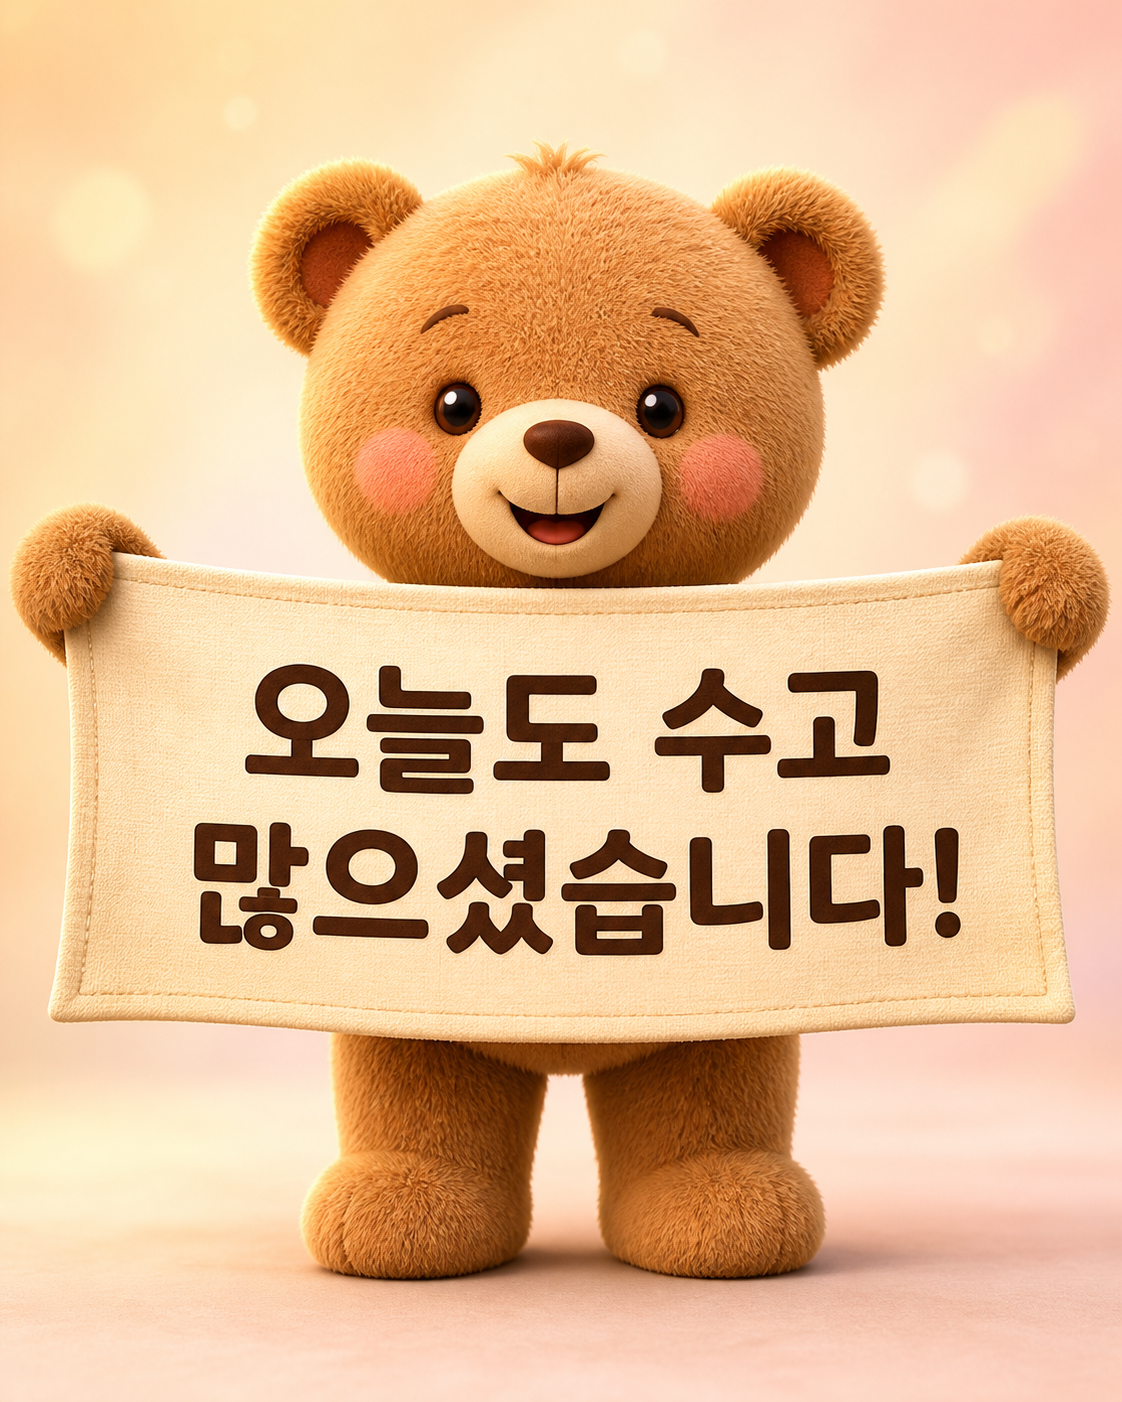

In [3]:
import base64
from IPython.display import display, Image

image_outputs = [
    item.result
    for item in response.output
    if item.type == "image_generation_call" and item.result is not None
]

if not image_outputs:
    raise RuntimeError("이미지 생성 결과가 없습니다. 모델/도구 지원 여부와 응답을 확인하세요.")

image_bytes = base64.b64decode(image_outputs[0])
filename = "teddy_bear_banner.png"
with open(filename, "wb") as f:
    f.write(image_bytes)

print(f"이미지 저장 완료: {filename}")
display(Image(data=image_bytes))

## Cell 5. 생성 이미지 다운로드

In [ ]:
from google.colab import files
files.download("teddy_bear_banner.png")